### 0. Adjustment of project

In [1]:
import meep as mp
import torch
from configs import conf_test as conf
from lib import numpy_functions as nf
from lib import core_finctions as cf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
from autograd import numpy as npa
import numpy as np
mp.verbosity(0)

1

In [2]:
"""
objective function
"""

def J(FF):
    """
    FF: an array of shapes (n_points, n_waves, n_fields). 
    penalty_coef: penalty coefficient (selected empirically).
    """
    # calculate the point‑by-point intensity: shape = (n_points, n_waves)
    I = npa.abs(FF[0, :, 2])**2 / angIPlane_base_mean[global_index_angle] / IAiry_norm_max

    # the basic goal is the wave average
    J_base = npa.mean(I)
    
    # penalty for the spread between waves (variance or std^2)
    penalty = penalty_coef * (npa.std(I))**2 
    print(f"penalty: {penalty}")

    return J_base - penalty

class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):

        # Forward pass for both single- and multi-frequency optimization.
        # Unwraps torch tensors to numpy arrays, calls external opt(), and saves gradients.

        rho_list = []
        shapes = []
        # Extract data and shapes
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            # if extra leading dim, squeeze it
            if arr.ndim > 1 and arr.shape[0] == 1:
                arr = arr.squeeze(0)
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())

        # Call external optimizer: returns objective and gradients
        f0, grad_rho = opt(rho_list)

        # Save context for backward
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype
        
        # print(f"shapes len = {len(shapes)}")
        # print("shapes:", ctx.shapes)
        # print("returned grad shapes:", [g.shape for g in ctx.grad_rho])
        missing = set(range(len(ctx.shapes))) - set(range(len(ctx.grad_rho)))
        print("Missing gradient indices:", missing)

        # Return scalar objective as torch tensor
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        # Backward pass: reshape and convert numpy gradients to torch,
        # handling both single- and multi-frequency cases.

        grads = []
        for g_np, shape in zip(ctx.grad_rho, ctx.shapes):
            # For multi-frequency, collapse along freq axis
            if g_np.ndim == 2:
                # average gradients over frequencies
                g_arr = np.mean(g_np, axis=1).reshape(shape)
            else:
                # single-frequency gradient
                g_arr = np.asarray(g_np, dtype=np.float64).reshape(shape)

            # Convert to torch tensor and scale by upstream grad_output
            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)
    
        # Add zeros for "lost" inputs
        n_missing = len(ctx.shapes) - len(grads)
        if n_missing > 0:
            for idx in range(n_missing):
                shape = ctx.shapes[len(grads) + idx]
                zero = torch.zeros(shape, device=ctx.device, dtype=ctx.dtype)
                grads.append(zero)
            
        # Return gradient for each input
        return tuple(grads)

def opt_torch(*x_tensors):
    # Apply the OptFunction in a torch-friendly way.
    return OptFunction.apply(*x_tensors)

## Main program
### 1.1 Normalization and comparison calculations

In [3]:
"""
Base parameters
"""
# 1. Shape
global_index_angle = None

a_initial_params = 1.0
h_initial_params = 1.0 # For 1 param optimization mode adj cell height
rt_np_global = nf.calculate_radii_step(D=conf.aperture, orders=conf.orders)

global_a_params = torch.full((conf.orders,), a_initial_params, dtype=torch.float64)
global_h_params = torch.full((conf.orders,), h_initial_params, dtype=torch.float64)

angle_in_rad = np.radians(conf.angle_list)
angle_in_deg = conf.angle_list
angle_after_refraction_in_radii = my_sources.refraction_input(angle_in_deg, conf.in_epsilon)
angle_after_refraction_in_deg = np.rad2deg(angle_after_refraction_in_radii)

# 2. Sources
    # A complete set of sources for all n_angels corners.
    # src is the only plane wave with one long wave
    # batch is a group of continuous plane waves with different wavelengths at the same angle
    # stack is a group with different wave angles of a group of waves with different wavelengths
    
stack_batch_src = []
for angle in angle_after_refraction_in_radii:
    src = my_sources.BatchEigenmodeSource(
        frequencies=conf.inc_frequents_array,
        df = conf.inc_df,
        resolution=conf.sim_resolution,
        diaphragm=conf.diaphragm,
        center=mp.Vector3(x=conf.main_source_center.x, y = 0 ),
        angle_in_rad=angle,
        epsilon=conf.in_epsilon,
        verbose=False,
    )
    batch_src = src.get_sources()
    stack_batch_src.append(batch_src)


# 3 Initializing the parameters
p_min, p_max = 0.01, 100.0
h_min, h_max = 0.01, conf.at_hei

    #start the decoders for the reverse transition to [p_min, p_max] and [h_min, h_max]
decoder_a = my_decoders.SigmoidDecoder(pmin=p_min, pmax=p_max)
decoder_h = my_decoders.SigmoidDecoder(pmin=h_min, pmax=h_max)

# 4. Local monitor
locNearRegion = mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(x = 0, y=conf.loc_cell.y)) # монитор

# 5. GUI output
panel = my_gui.LiveInfoPanel()
panel.show()

# 6. Save and load
# "name" if you load, None if you save

"""
Examples

filename_focus_IAiry = "focusAiry_D500.0_f500.0_diaph500_res5_nfreq3.npy"
filename_base_IAiry = "baseAiry_D500.0_f500.0_diaph500_res5_nfreq3.npy"
file_name_IBase = "basePlane_D500.0_f500.0_diaph500_res5_nfreq3.npy"

filename_focus_IAiry = None
filename_base_IAiry = None
file_name_IBase = None
"""

# filename_focus_IAiry = None
# filename_base_IAiry = None
# file_name_IBase = None

# filename_focus_IAiry = "focusAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"
# filename_base_IAiry = "baseAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"
# file_name_IBase = "basePlane_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"

# filename_focus_IAiry = "focusAiry_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"
# filename_base_IAiry = "baseAiry_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"
# file_name_IBase = "basePlane_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"

# filename_focus_IAiry = "focusAiry_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"
# filename_base_IAiry = "baseAiry_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"
# file_name_IBase = "basePlane_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"

filename_focus_IAiry = "focusAiry_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy"
filename_base_IAiry = "baseAiry_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy"
file_name_IBase = "basePlane_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy"

HTML(value='\n        \n        <style>\n            .live-panel { \n                border: 2px solid #4CAF50…

Data from focusAiry_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy loaded successfully.
Data from baseAiry_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy loaded successfully.


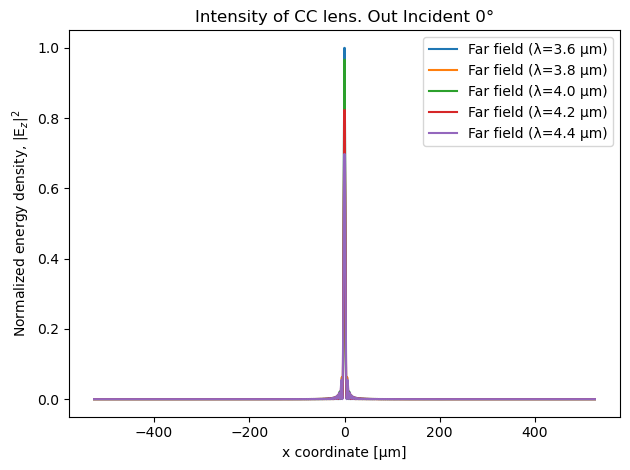

Data from basePlane_D20000.0_f1000.0_diaph1052_res5_nfreq5.npy loaded successfully.


In [4]:
"""
Normalization
"""
# AIRY wave
IAiry, IAiry_base, sim = nf.get_IAiry_simulation(
    monitor =  locNearRegion,
    cell = conf.loc_cell,
    filename_focus_airy = filename_focus_IAiry,
    filename_base_airy= filename_base_IAiry,
    resolution = conf.sim_resolution,
    epsilon = 1,
    get_base=True,
    symmetries=[mp.Mirror(mp.Y)]
)
IAiry_norm = IAiry/IAiry_base
IAiry_norm_max = IAiry_norm.max(axis=0)
abscissa = nf.get_abscissa(conf.spot_ff, IAiry_norm, 0, 0)
nf.plot_intensity(
    IAiry_norm/IAiry_norm.max(),
    out_angle_in_deg=0,
    wavelength_array=conf.inc_wavelength_array,
    abscissa=abscissa,
    isfwhm=False,
)

# IBase for normalization
angIPlane_base = nf.get_Ibase_batch_simulation(
    monitor =  locNearRegion,
    sources_batch=stack_batch_src,
    cell=conf.loc_cell,
    frequents_array=conf.inc_frequents_array,
    filename= file_name_IBase,
    symmetries = None,
    verbose = True,
)
angIPlane_base_mean = np.mean(angIPlane_base, axis=1)

### 1.2 Optimizer

angle: 0.0
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.002246262888204855 | beta = 2.14 ||grad|| = 0.000992198827574182 || wait = 0
Mean effective LR = 4.422e+05
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (59 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 17 (41) | f0 = 0.22025576641352132 | beta = 6.317630421929978 ||grad|| = 0.0028183589346119555 || wait = 5
Mean effective LR = 2.329e+04
lr = 0.662
Early stopping at step 17: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 0.22696448751401305 at step 11
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param0.pdf


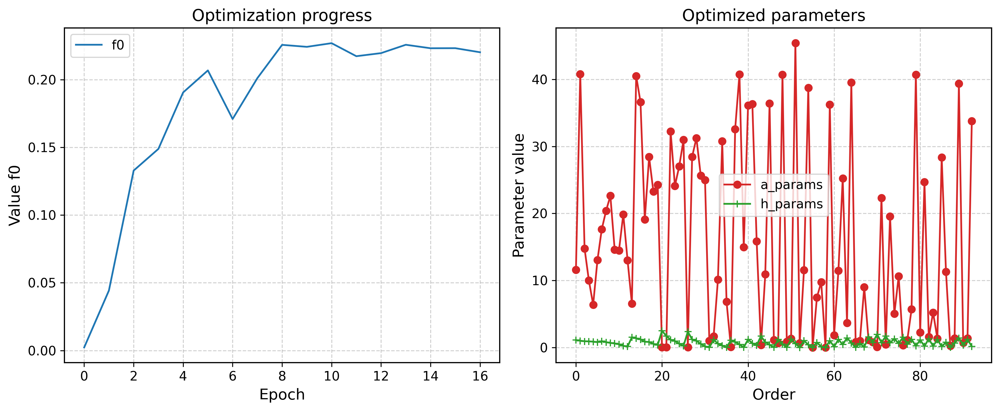

angle: 14.735101732001636
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.00865510502409008 | beta = 2.14 ||grad|| = 0.002584580382114854 || wait = 0
Mean effective LR = 1.185e+05
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (55 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 16 (41) | f0 = 0.16817919969768846 | beta = 5.90432749713082 ||grad|| = 0.0051673041204081 || wait = 5
Mean effective LR = 2.124e+04
lr = 0.762
Early stopping at step 16: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 0.17429639188813068 at step 11
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param1.pdf


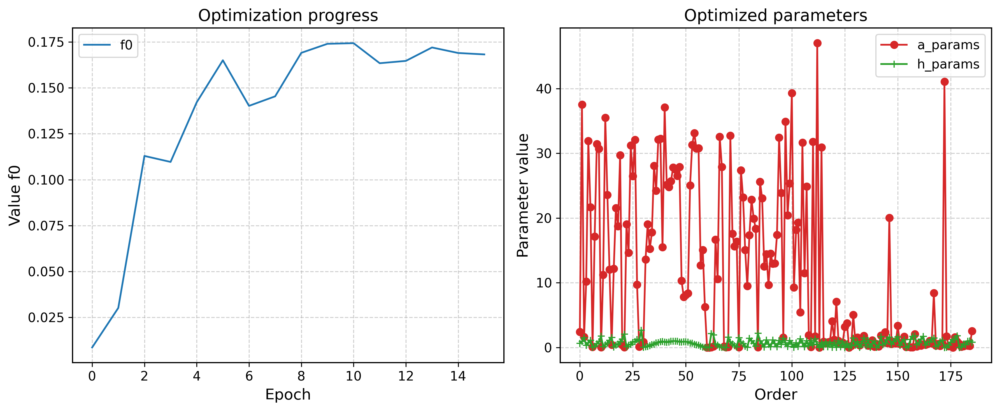

angle: 27.744370169482565
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.006999198229366385 | beta = 2.14 ||grad|| = 0.0016217366930038743 || wait = 0
Mean effective LR = 1.583e+05
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (79 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 22 (41) | f0 = 0.08952681343076016 | beta = 8.860803482200867 ||grad|| = 0.0037251209125426306 || wait = 5
Mean effective LR = 2.291e+04
lr = 0.662
Early stopping at step 22: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 0.09556813474847335 at step 16
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param2.pdf


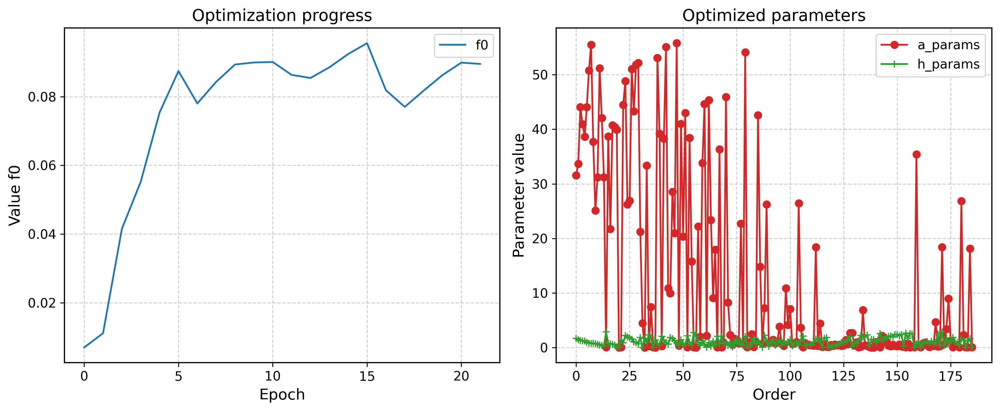

angle: 38.27343992319898
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.00235677512689502 | beta = 2.14 ||grad|| = 0.001484303147967913 || wait = 0
Mean effective LR = 8.972e+04
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (39 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 12 (41) | f0 = 0.1798890602512005 | beta = 4.50438317792165 ||grad|| = 0.005917697098412476 || wait = 5
Mean effective LR = 7.526e+03
lr = 0.662
Early stopping at step 12: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 0.2144689122193902 at step 6
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param3.pdf


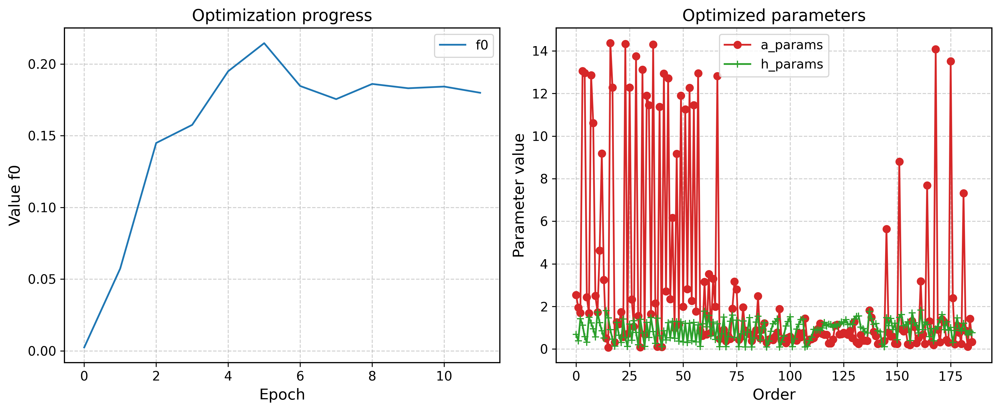

angle: 46.45162915260831
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.038693100391701624 | beta = 2.14 ||grad|| = 0.028214978452383885 || wait = 0
Mean effective LR = 5.677e+03
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (59 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 17 (41) | f0 = 4.943280056451271 | beta = 6.317630421929978 ||grad|| = 0.17239840039045698 || wait = 5
Mean effective LR = 3.176e+02
lr = 0.662
Early stopping at step 17: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 5.224979592574759 at step 11
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param4.pdf


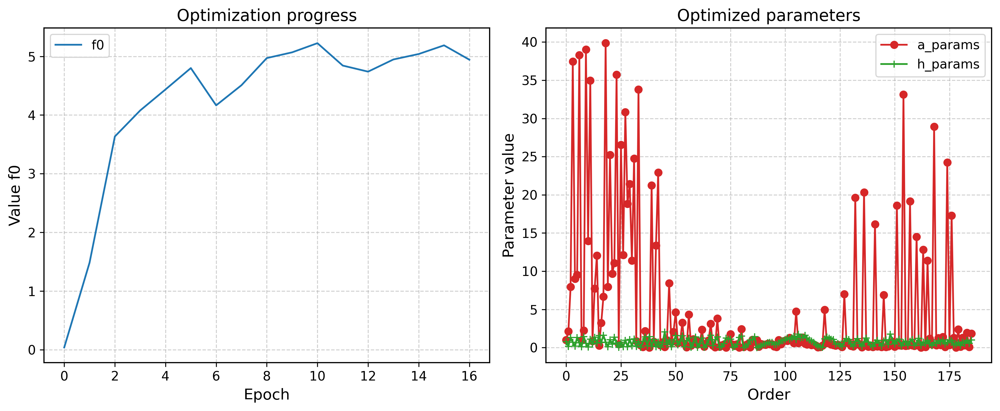

angle: 52.748598564570045
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.25003011822940885 | beta = 2.14 ||grad|| = 0.151508133035572 || wait = 0
Mean effective LR = 2.484e+03
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (99 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 27 (41) | f0 = 15.646926296806175 | beta = 12.427735259353419 ||grad|| = 0.8299662357746034 || wait = 5
Mean effective LR = 1.479e+02
lr = 0.662
Early stopping at step 27: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 16.989991932128742 at step 21
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param5.pdf


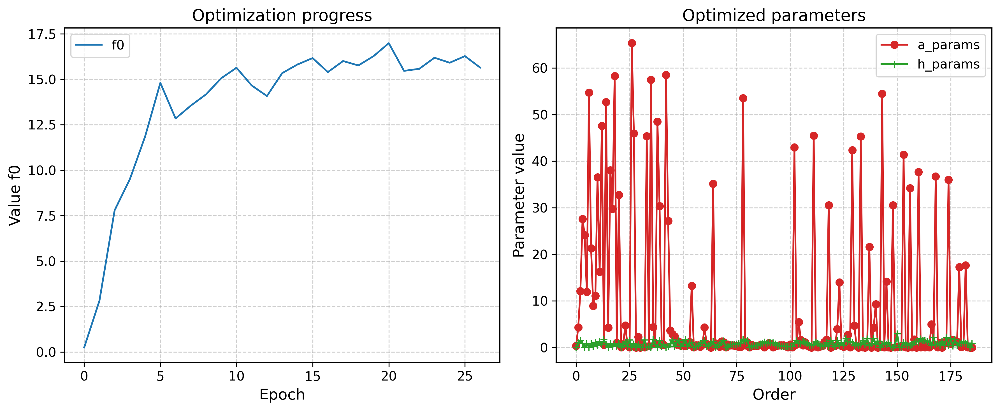

angle: 57.637010464894324
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 2.7680773467218955 | beta = 2.14 ||grad|| = 1.1401666637987435 || wait = 0
Mean effective LR = 9.528e+02
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (99 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 27 (41) | f0 = 66.0102229392366 | beta = 12.427735259353419 ||grad|| = 2.9114849554486515 || wait = 5
Mean effective LR = 3.257e+01
lr = 0.662
Early stopping at step 27: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 72.722346476133 at step 21
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param6.pdf


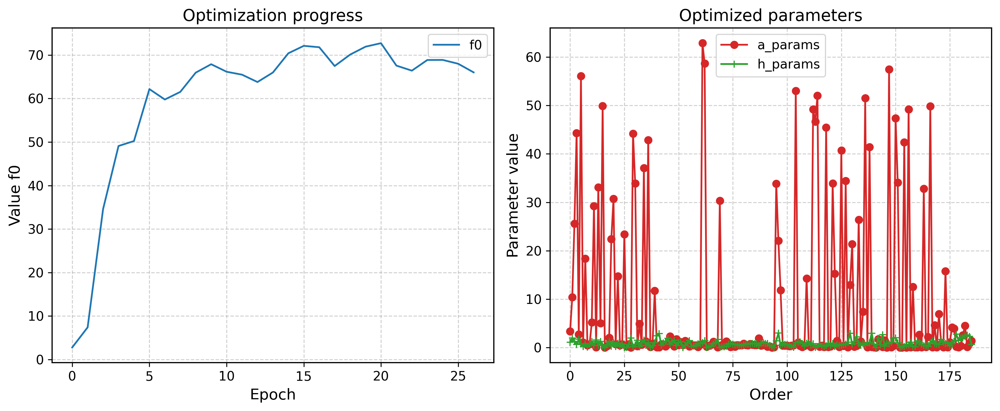

angle: 61.489940439172564
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.9693724112317806 | beta = 2.14 ||grad|| = 0.46458349308731256 || wait = 0
Mean effective LR = 2.994e+03
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (95 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 26 (41) | f0 = 29.19068094929644 | beta = 11.614705849863007 ||grad|| = 1.366043773079881 || wait = 5
Mean effective LR = 7.674e+01
lr = 0.762
Early stopping at step 26: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 30.67749777518092 at step 20
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param7.pdf


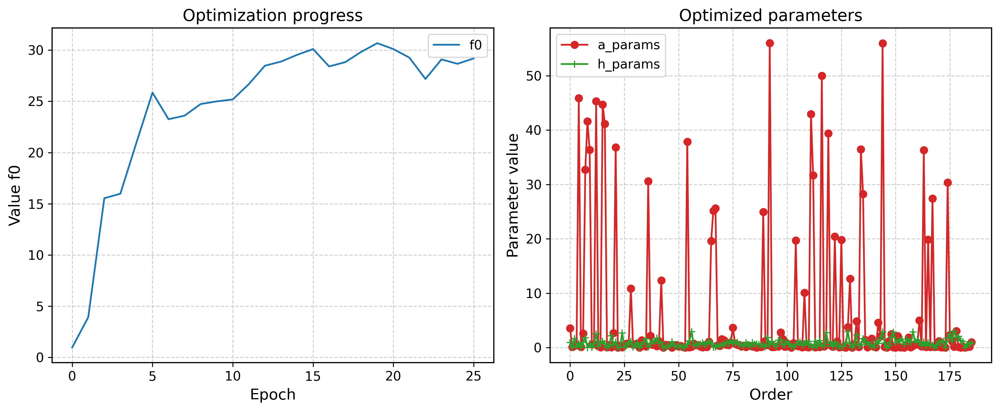

angle: 64.5789521248291
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.19675377928529736 | beta = 2.14 ||grad|| = 0.10003858435082304 || wait = 0
Mean effective LR = 1.101e+03
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (91 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 25 (41) | f0 = 10.506893807017047 | beta = 10.8548652802458 ||grad|| = 0.43717407250521284 || wait = 5
Mean effective LR = 1.492e+02
lr = 0.800
Early stopping at step 25: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 12.045964160740636 at step 19
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param8.pdf


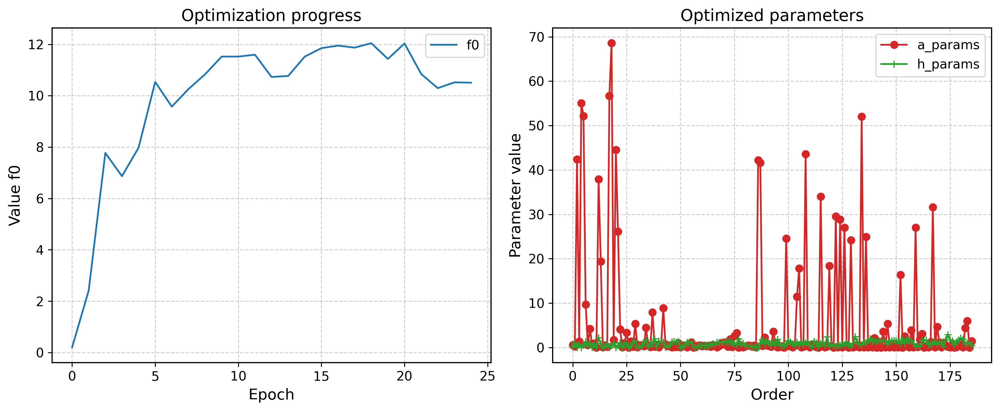

angle: 67.09712323501574
penalty coef = 0.0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  1 (41) | f0 = 0.34897766828981047 | beta = 2.14 ||grad|| = 0.16265832999889585 || wait = 0
Mean effective LR = 9.806e+02
lr = 0.762
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (79 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

penalty: 0.0
Starting adjoint run...
penalty: Autograd ArrayBox with value 0.0


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step 22 (41) | f0 = 22.204496195201976 | beta = 8.860803482200867 ||grad|| = 1.1682039474536987 || wait = 5
Mean effective LR = 5.425e+01
lr = 0.662
Early stopping at step 22: f0 hasn't improved by >0.001 for 6 steps

Best f0 = 25.016848222788386 at step 16
[Tensor] Saved NumPy array to ./global_a_params_1786.npy
[Tensor] Saved Torch tensor to ./global_a_params_1786.pt
[Tensor] Saved NumPy array to ./global_h_params_1786.npy
[Tensor] Saved Torch tensor to ./global_h_params_1786.pt
Optimization plot saved to: opt_progress_and_param9.pdf


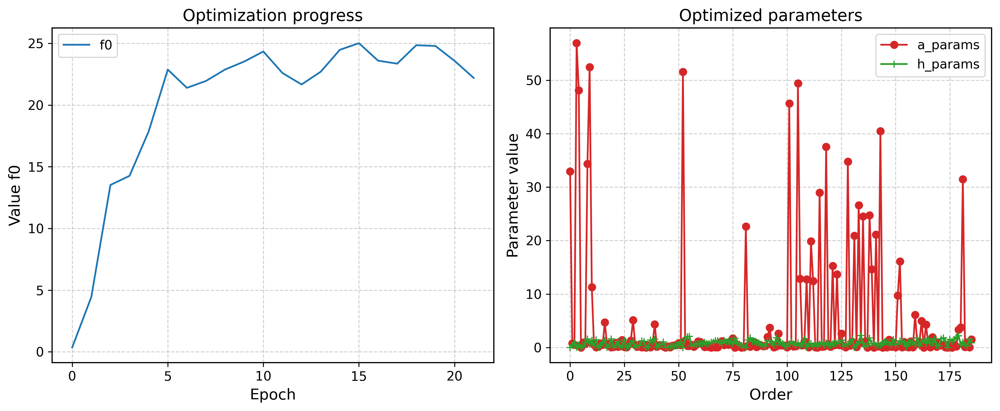

In [5]:
# ____ Multi-angels _____
opt_zone_start = 0
# opt_zone_end = 1
opt_zone_end = conf.n_angles
loc_symmetry = None # symmetry - off - faster simulation
is_center=None
lr = None
beta = None
num_steps = 40  # number of epochs

# ### Penalty adj start ###
# # --- опорные точки ---
# 
# angles_ref = np.array([0.0, 20.0, 40.0])
# penalty_ref = np.array([20.0, 5.0, 0.05]) 
# penalty_min = 0.05
# angle_saturation = 40.0
# 
# # аппроксимация в log-пространстве
# log_penalty_ref = np.log(penalty_ref)
# 
# # решаем систему для квадратичной функции
# # log(penalty) = a*angle^2 + b*angle + c
# A = np.vstack([
#     angles_ref**2,
#     angles_ref,
#     np.ones_like(angles_ref)
# ]).T
# 
# a, b, c = np.linalg.solve(A, log_penalty_ref)
# 
# ### Penalty adj end ###

for i in range(opt_zone_start, opt_zone_end):
    global_index_angle = i
    angle = angle_in_deg[i]

    is_center = (angle == 0)

    # if angle <= angle_saturation:
    #     log_penalty = a * angle**2 + b * angle + c
    #     penalty_coef = np.exp(log_penalty)
    # else:
    #     penalty_coef = penalty_min

    lr = 0.8
    beta = 2.0
    
    penalty_coef = 0.0
    print(f"angle: {angle}")
    print(f"penalty coef = {penalty_coef}")

    loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
    loc_rt_np = rt_np_global[:loc_orders]
    loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
    resolutions = nf.AdaptiveResolution(
        drt=loc_drt_np,
        x_dim=conf.x_dim,
        h_dim= conf.h_dim,
    ).generate()

    # 0.0) Extract local params
    loc_a_params = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
    loc_h_params = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
    # 0.1) Initializing the optimizer
    opt = cf.init_opt(i, J, NearRegion=locNearRegion,stack_batch_src=stack_batch_src, resolutions = resolutions, a_initial=loc_a_params, h_initial=loc_h_params, rt_np = loc_rt_np, drt_np = loc_drt_np, midrt_np = loc_midrt_np, is_center = is_center, symmetry = loc_symmetry, is_plot = False, is_plot_cross=False)
    # 0.2) Initial hyper params
    loc_optimizer, scheduler, store_loc_history, loc_u_a, loc_u_h = cf.init_loc_opt_hyper(a_initial=loc_a_params, h_initial=loc_h_params, p_min=p_min, p_max=p_max, h_min=h_min, h_max=h_max, lr=lr, regime=2)
    # 1) Begin optimization loop
    loc_history, loc_best_a_params, loc_best_h_params  = cf.run_loc_opt(opt_torch, loc_rt_np, loc_drt_np , loc_optimizer,scheduler, loc_u_a, loc_u_h, store_loc_history, beta, num_steps, decoder_a, decoder_h, resolutions, regime=2)    
    # 2) Update global_params
    cf.update_global_params(i, global_a_params, global_h_params, loc_best_a_params, loc_best_h_params, is_save = True)
    # # 3) Save history
    # help_functions.save_history(loc_history, save=True, index=global_index_angle)
    # 4) Visualise
    cf.viz_loc_opt(loc_history, loc_best_a_params,loc_best_h_params, save_path=f"opt_progress_and_param{i}.pdf", save_format="pdf")

### 1.3. TEST

In [5]:
# global_a_params = torch.load("global_a_params_1786.pt", weights_only=True)
# global_h_params = torch.load("global_h_params_1786.pt", weights_only=True)

test region: 0 || angle: 0.0 || include elements: 93


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane0.pdf


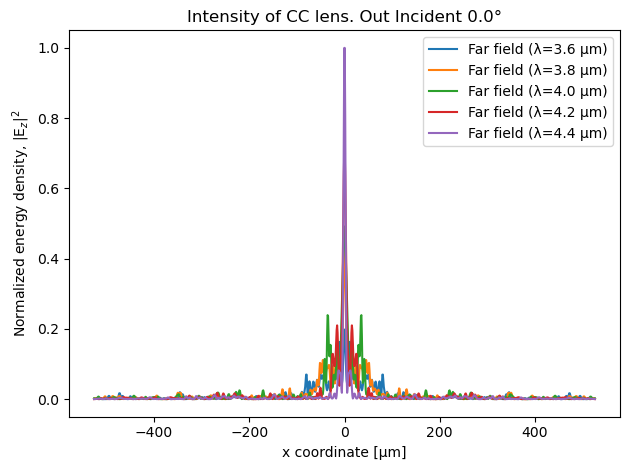

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 7.01 µm
λ=4.4: FWHM = 7.01 µm
📄 Figure saved to: psf_plot_deep0.pdf


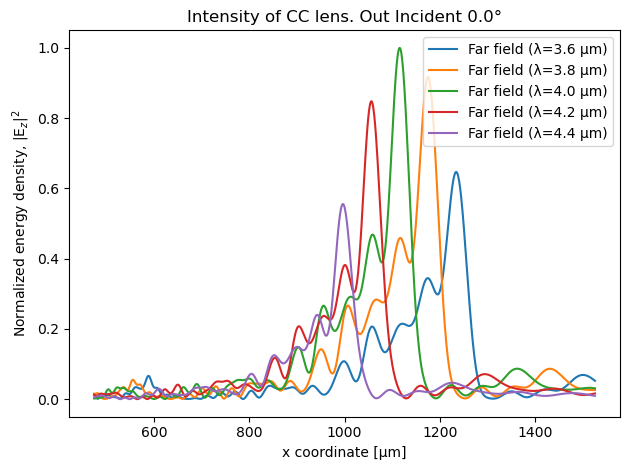

λ=3.6: FWHM = 33.03 µm
λ=3.8: FWHM = 49.05 µm
λ=4.0: FWHM = 51.05 µm
λ=4.2: FWHM = 42.04 µm
λ=4.4: FWHM = 18.02 µm
PSF plot saved to: psf_plot0.pdf
MTF plot saved to: mtf_plot0.pdf


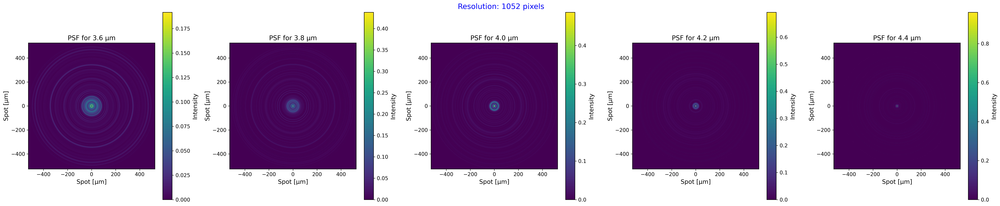

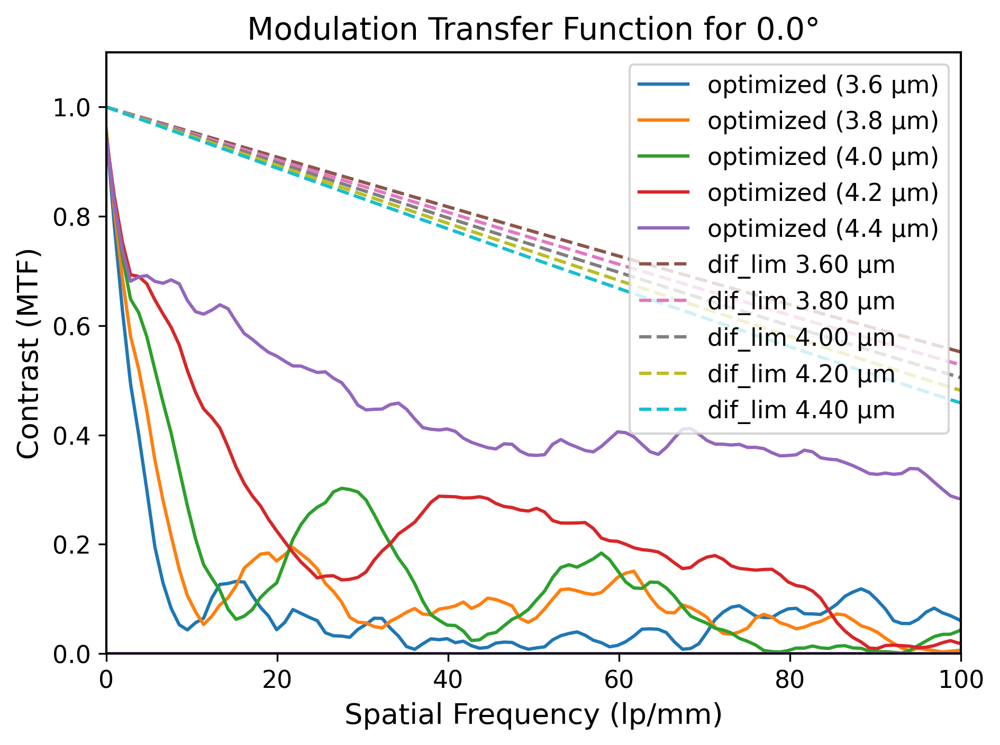

EFFICIENCY PLANE: 0
arr_STREHL: [0.06311056 0.11563702 0.12684298 0.23117614 0.52331338]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.0963471  0.17861841 0.23743996 0.35388218 0.56304458]
arr_EER_rel: [0.10888922 0.20334328 0.2718715  0.40676292 0.63817541]
mean STREHL: 0.2120160162492369 +- 0.16491776596435168
mean EER_rel: 0.32580846870486513 +- 0.18389540993729872
EFFICIENCY DEEP: 0
arr_STREHL: [0.02956036 0.03293958 0.03647266 0.04008971 0.04379756]
arr_EER_test: [0.01178379 0.02027251 0.02139085 0.03802089 0.10324388]
arr_EER_rel: [0.01331776 0.02307869 0.02449277 0.04370237 0.1170204 ]
mean STREHL: 0.036571976357189694 +- 0.005038856937637112
mean EER_rel: 0.044322398532828676 +- 0.03765947651897646
test region: 1 || angle: 14.735101732001636 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane1.pdf


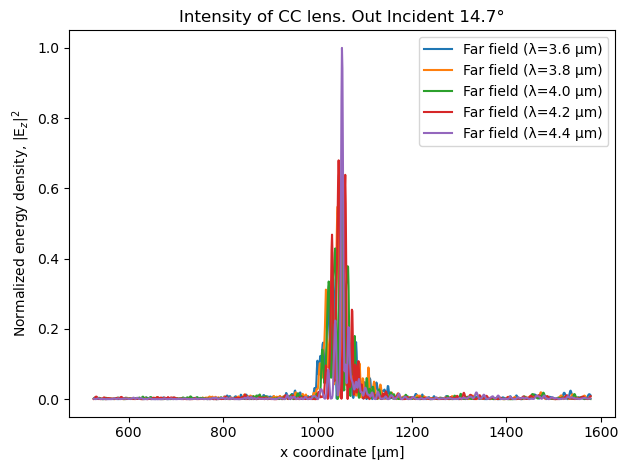

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 4.00 µm
λ=4.0: FWHM = 5.00 µm
λ=4.2: FWHM = 6.01 µm
λ=4.4: FWHM = 6.01 µm
📄 Figure saved to: psf_plot_deep1.pdf


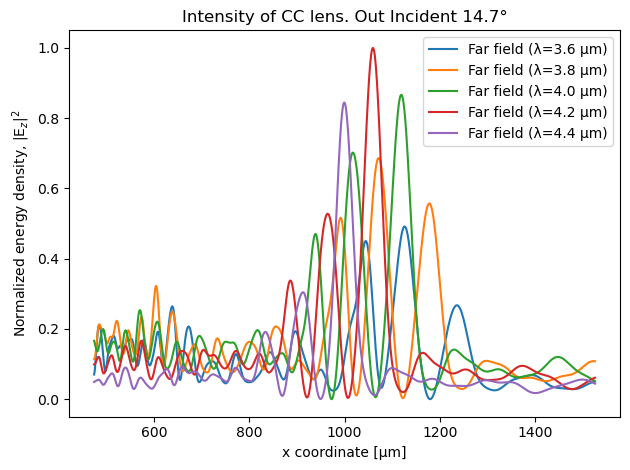

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 33.03 µm
λ=4.0: FWHM = 44.04 µm
λ=4.2: FWHM = 46.04 µm
λ=4.4: FWHM = 37.04 µm
MTF plot saved to: mtf_plot1.pdf


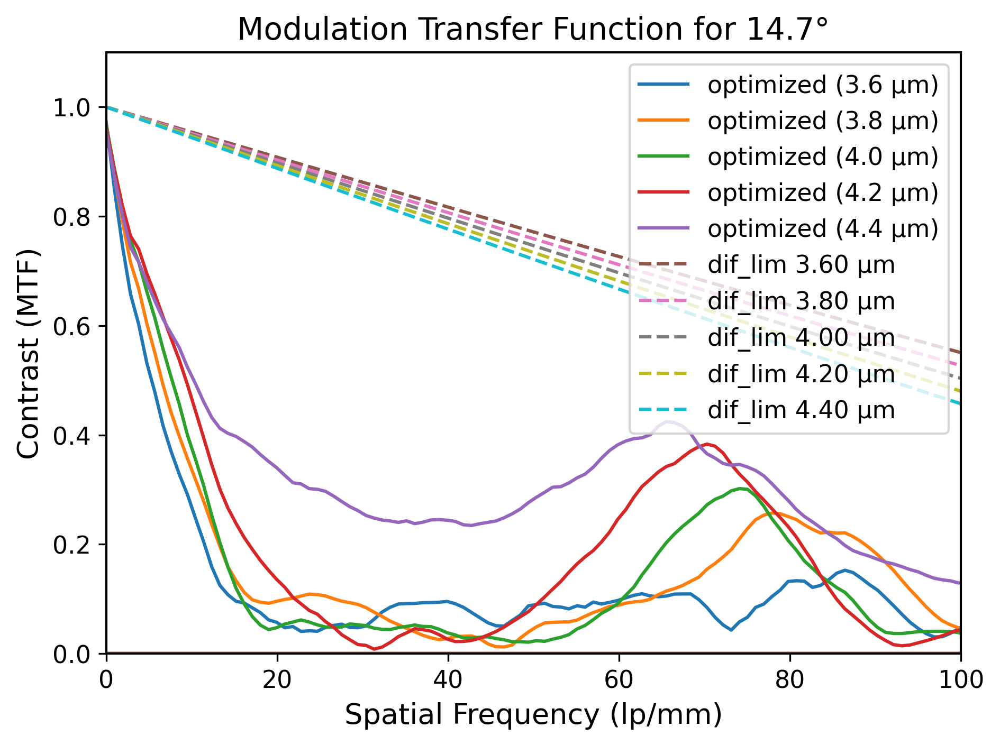

EFFICIENCY PLANE: 1
arr_STREHL: [0.08464551 0.12562119 0.13258939 0.18389927 0.39603696]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.09126775 0.16465408 0.18432116 0.09611324 0.42902385]
arr_EER_rel: [0.10314867 0.18744597 0.21104986 0.11047548 0.48627139]
mean STREHL: 0.18455846422906783 +- 0.1103454335018214
mean EER_rel: 0.219678275096367 +- 0.1397781542147839
EFFICIENCY DEEP: 1
arr_STREHL: [0.01563591 0.01692208 0.02101024 0.0308888  0.04189673]
arr_EER_test: [0.00901712 0.02477352 0.02517115 0.00320532 0.09991369]
arr_EER_rel: [0.01019093 0.02820274 0.02882125 0.0036843  0.11324585]
mean STREHL: 0.025270752731230216 +- 0.009886028945067443
mean EER_rel: 0.03682901288957326 +- 0.039461953489568054
test region: 2 || angle: 27.744370169482565 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane2.pdf


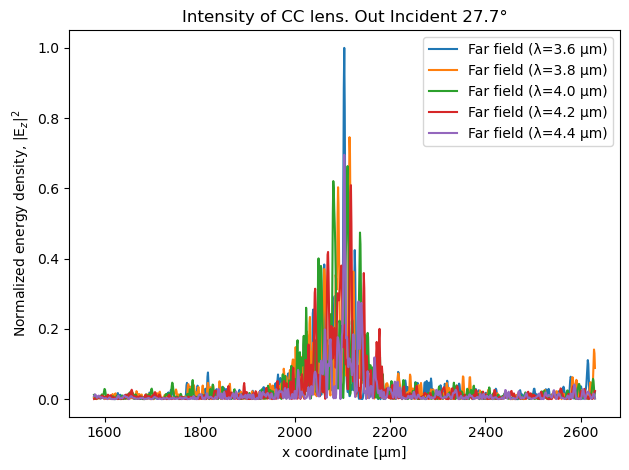

λ=3.6: FWHM = 6.01 µm
λ=3.8: FWHM = 5.00 µm
λ=4.0: FWHM = 5.00 µm
λ=4.2: FWHM = 4.00 µm
λ=4.4: FWHM = 4.00 µm
📄 Figure saved to: psf_plot_deep2.pdf


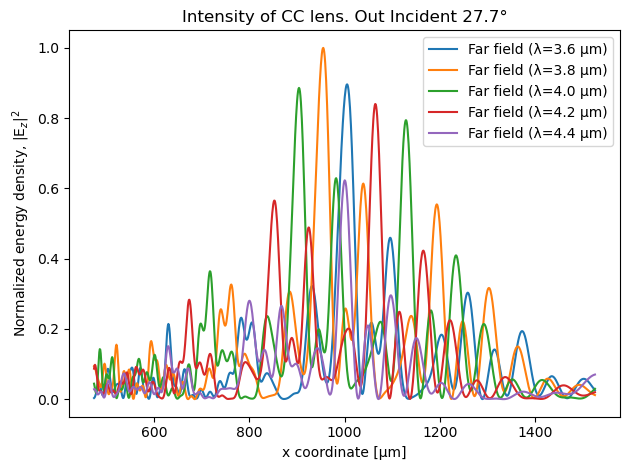

λ=3.6: FWHM = 36.03 µm
λ=3.8: FWHM = 35.03 µm
λ=4.0: FWHM = 30.03 µm
λ=4.2: FWHM = 26.02 µm
λ=4.4: FWHM = 18.02 µm
MTF plot saved to: mtf_plot2.pdf


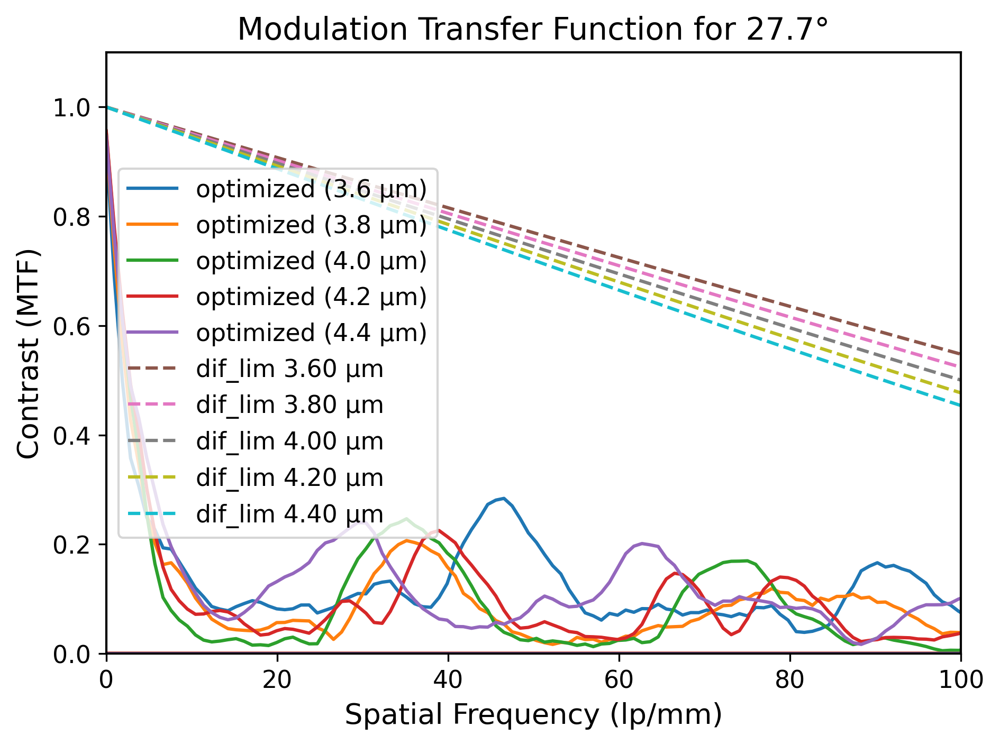

EFFICIENCY PLANE: 2
arr_STREHL: [0.1347636  0.08821235 0.08220113 0.09423615 0.15985484]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.1541084  0.04417591 0.0627431  0.05262987 0.18913248]
arr_EER_rel: [0.17416969 0.05029087 0.07184157 0.06049437 0.2143697 ]
mean STREHL: 0.11185361600790147 +- 0.030257360181940248
mean EER_rel: 0.11423324097145224 +- 0.06692269179741912
EFFICIENCY DEEP: 2
arr_STREHL: [0.03114859 0.02878918 0.02665343 0.03268909 0.03948511]
arr_EER_test: [0.07119915 0.01622861 0.01358873 0.01505209 0.09233993]
arr_EER_rel: [0.08046761 0.01847502 0.01555926 0.01730133 0.10466147]
mean STREHL: 0.031753079879094016 +- 0.004377600002947575
mean EER_rel: 0.04729293549634857 +- 0.03775898058330494
test region: 3 || angle: 38.27343992319898 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane3.pdf


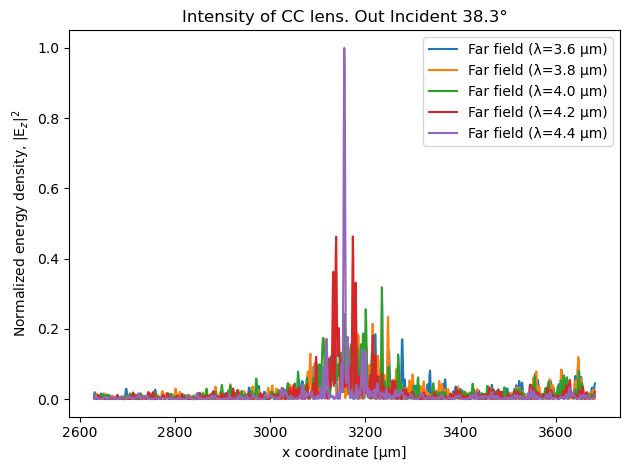

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 0.00 µm
λ=4.4: FWHM = 5.00 µm
📄 Figure saved to: psf_plot_deep3.pdf


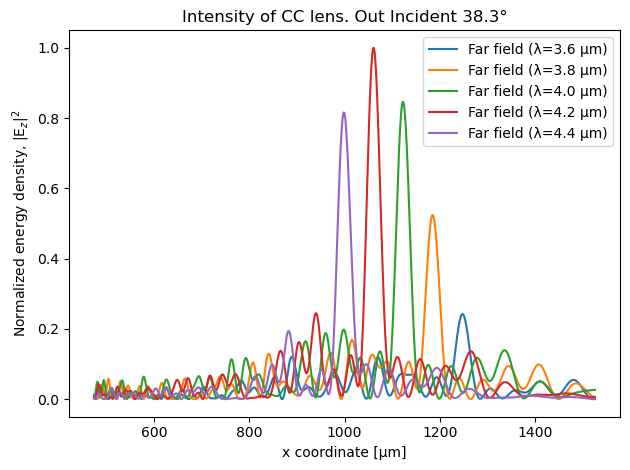

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 9.01 µm
λ=4.0: FWHM = 29.03 µm
λ=4.2: FWHM = 33.03 µm
λ=4.4: FWHM = 27.03 µm
MTF plot saved to: mtf_plot3.pdf


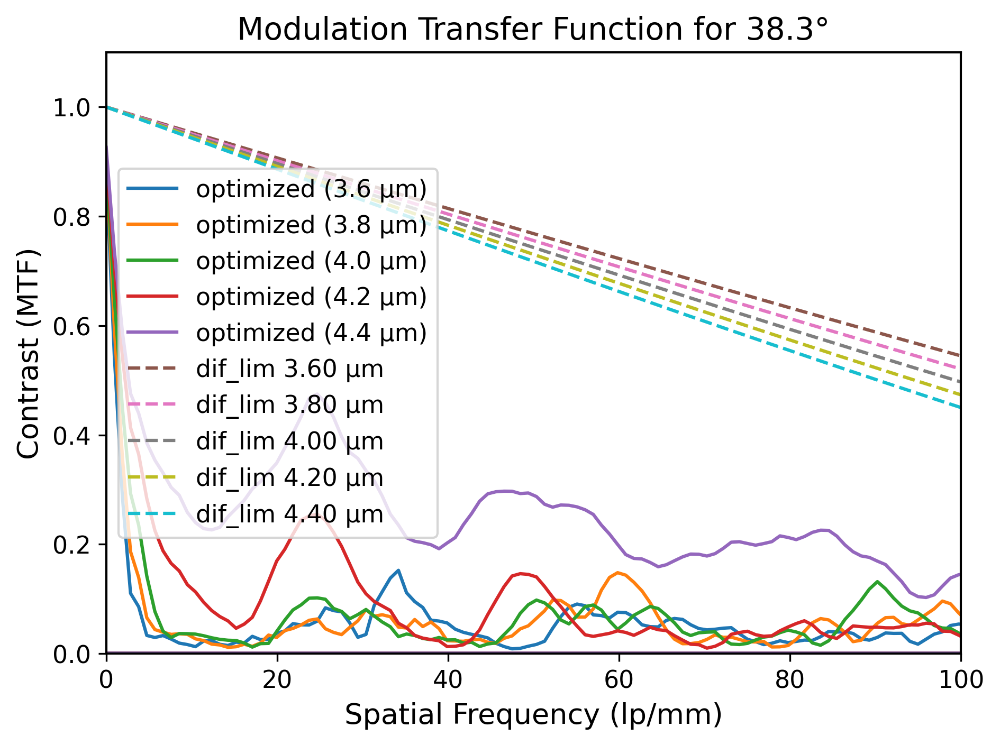

EFFICIENCY PLANE: 3
arr_STREHL: [0.03945234 0.04472116 0.06203634 0.11353627 0.38215314]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.012683   0.02820856 0.04826179 0.0360138  0.33398397]
arr_EER_rel: [0.01433403 0.03211327 0.0552603  0.04139536 0.3785497 ]
mean STREHL: 0.1283798490631594 +- 0.12956045119644102
mean EER_rel: 0.10433053191131672 +- 0.1377530969898834
EFFICIENCY DEEP: 3
arr_STREHL: [0.02673639 0.03751228 0.04834671 0.06079828 0.07536732]
arr_EER_test: [0.0061034  0.0064752  0.02417584 0.00493244 0.17695333]
arr_EER_rel: [0.00689792 0.00737152 0.02768162 0.0056695  0.2005654 ]
mean STREHL: 0.04975219878647486 +- 0.017086068770214815
mean EER_rel: 0.049637191947913786 +- 0.07590462728684803
test region: 4 || angle: 46.45162915260831 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane4.pdf


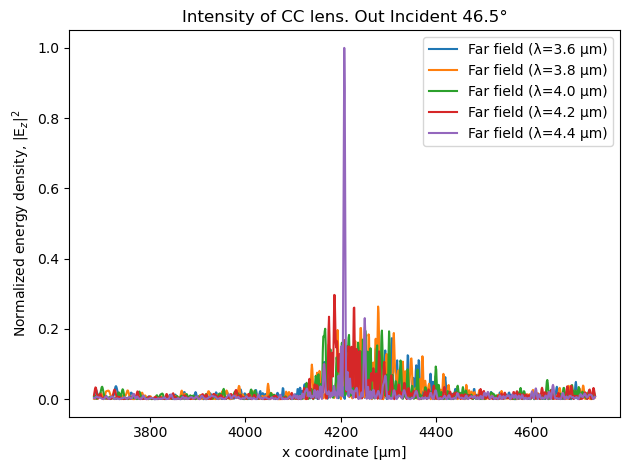

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 0.00 µm
λ=4.4: FWHM = 5.00 µm
📄 Figure saved to: psf_plot_deep4.pdf


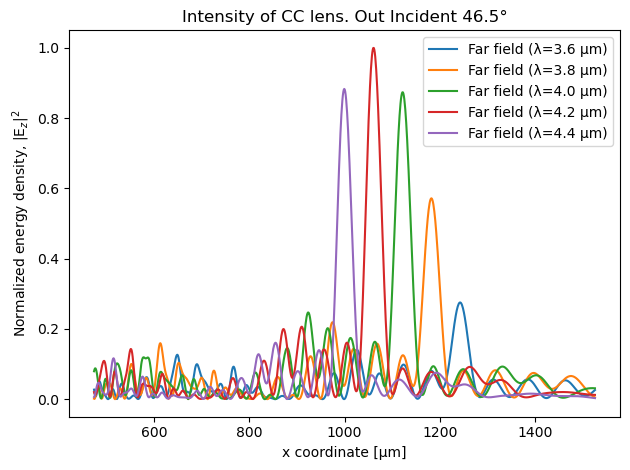

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 18.02 µm
λ=4.0: FWHM = 35.03 µm
λ=4.2: FWHM = 36.03 µm
λ=4.4: FWHM = 31.03 µm
MTF plot saved to: mtf_plot4.pdf


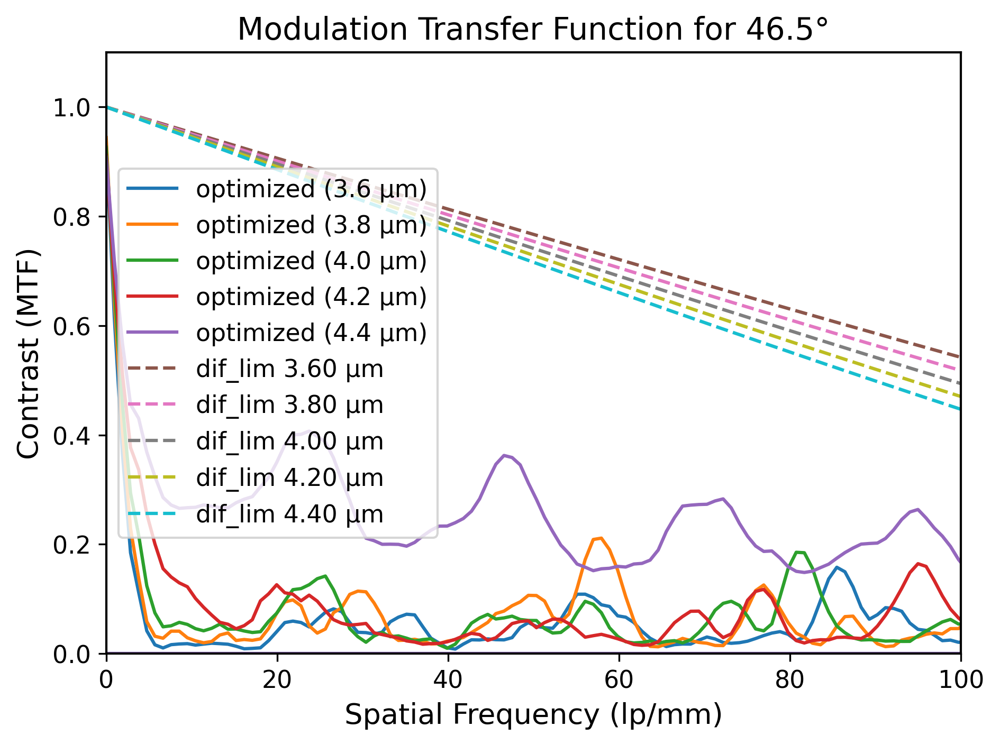

EFFICIENCY PLANE: 4
arr_STREHL: [0.04051877 0.05341595 0.04101404 0.07426352 0.36727371]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.02788984 0.03872836 0.04252234 0.04598813 0.31215146]
arr_EER_rel: [0.03152044 0.04408925 0.04868857 0.05286015 0.35380393]
mean STREHL: 0.11529719839810064 +- 0.12658200240445608
mean EER_rel: 0.10619246886236375 +- 0.124012249202488
EFFICIENCY DEEP: 4
arr_STREHL: [0.0257384  0.03466657 0.04506878 0.05769859 0.0708979 ]
arr_EER_test: [0.00094321 0.0062665  0.0102059  0.0170263  0.16780722]
arr_EER_rel: [0.001066   0.00713392 0.01168587 0.01957055 0.19019887]
mean STREHL: 0.04681404672694213 +- 0.016082879770971163
mean EER_rel: 0.04593104096126706 +- 0.07238632755894932
test region: 5 || angle: 52.748598564570045 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane5.pdf


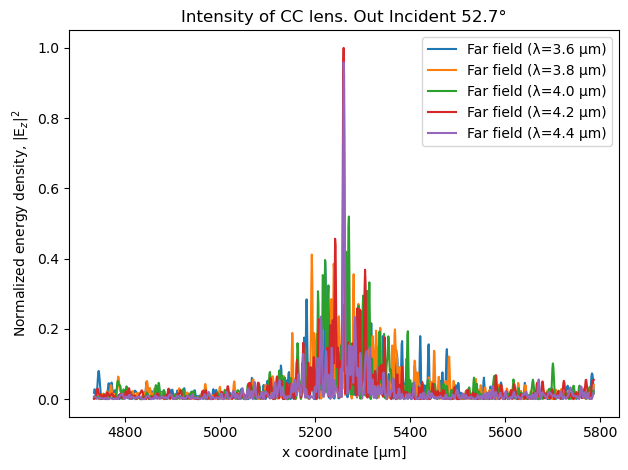

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 2.00 µm
λ=4.2: FWHM = 5.00 µm
λ=4.4: FWHM = 5.00 µm
📄 Figure saved to: psf_plot_deep5.pdf


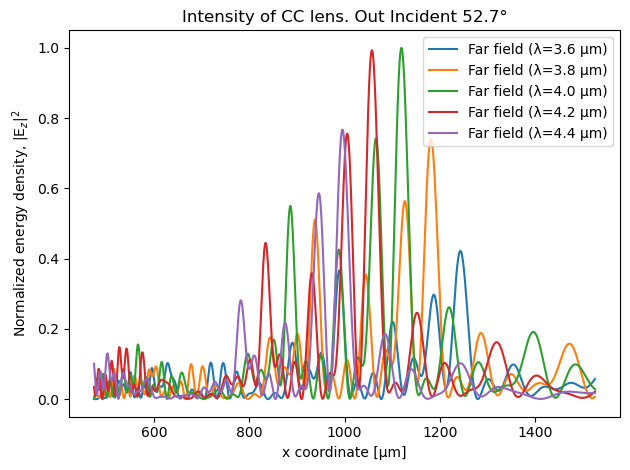

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 25.02 µm
λ=4.0: FWHM = 31.03 µm
λ=4.2: FWHM = 31.03 µm
λ=4.4: FWHM = 23.02 µm
MTF plot saved to: mtf_plot5.pdf


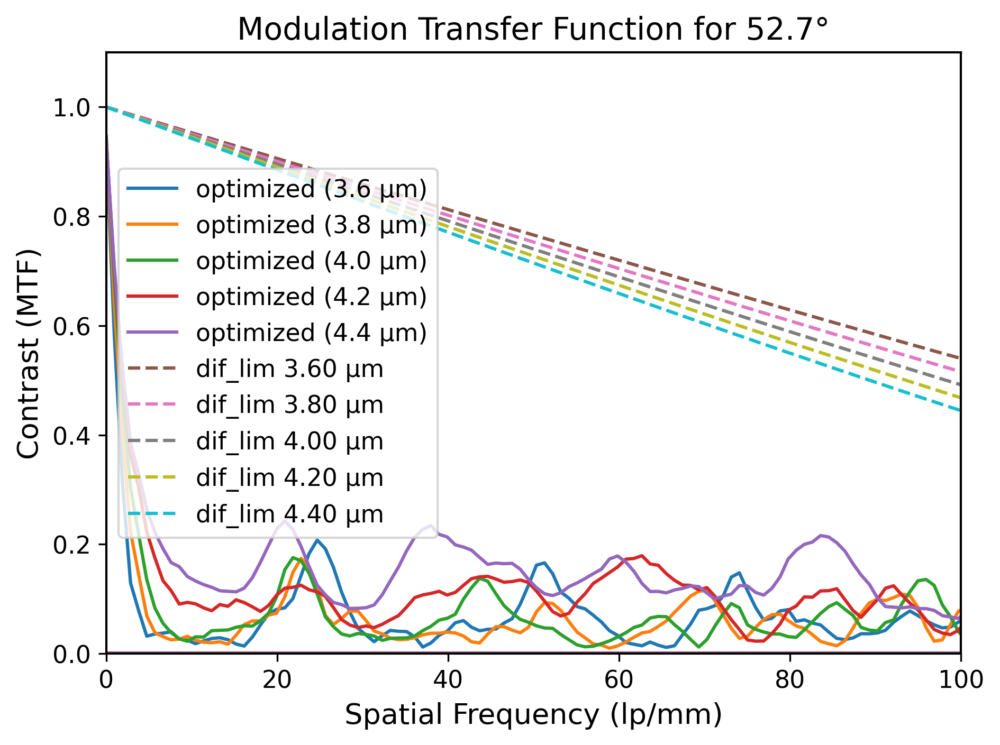

EFFICIENCY PLANE: 5
arr_STREHL: [0.05296667 0.05000417 0.06330498 0.14760331 0.21516427]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.06432254 0.01822402 0.05785105 0.13204412 0.19343731]
arr_EER_rel: [0.07269582 0.02074665 0.06624012 0.15177552 0.21924895]
mean STREHL: 0.10580867934726419 +- 0.06544986004791065
mean EER_rel: 0.10614141167699995 +- 0.07053903138524074
EFFICIENCY DEEP: 5
arr_STREHL: [0.02420427 0.02976388 0.03523147 0.04141116 0.04836798]
arr_EER_test: [0.0279471  0.00783335 0.01493449 0.05819662 0.10758985]
arr_EER_rel: [0.03158516 0.00891767 0.01710017 0.06689296 0.12194628]
mean STREHL: 0.03579575284210329 +- 0.008493034645107197
mean EER_rel: 0.04928844805792562 +- 0.041396550538689895
test region: 6 || angle: 57.637010464894324 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane6.pdf


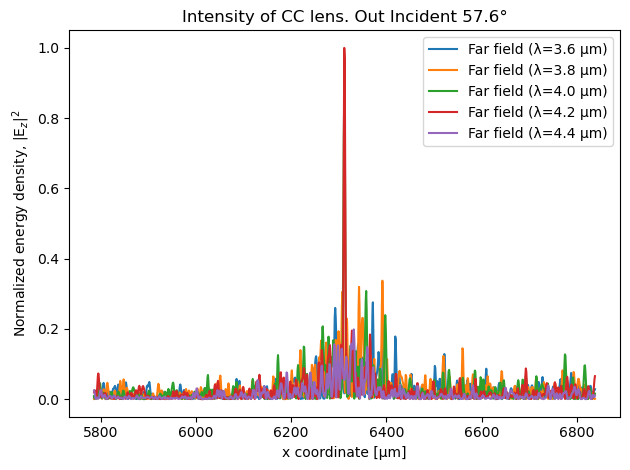

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 5.00 µm
λ=4.2: FWHM = 5.00 µm
λ=4.4: FWHM = 0.00 µm
📄 Figure saved to: psf_plot_deep6.pdf


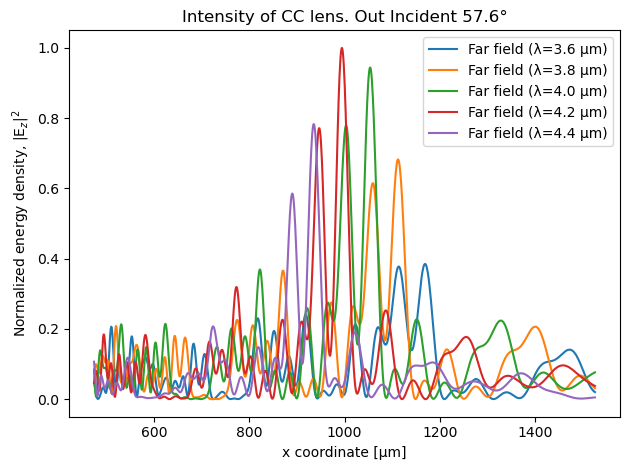

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 23.02 µm
λ=4.0: FWHM = 29.03 µm
λ=4.2: FWHM = 29.03 µm
λ=4.4: FWHM = 23.02 µm
MTF plot saved to: mtf_plot6.pdf


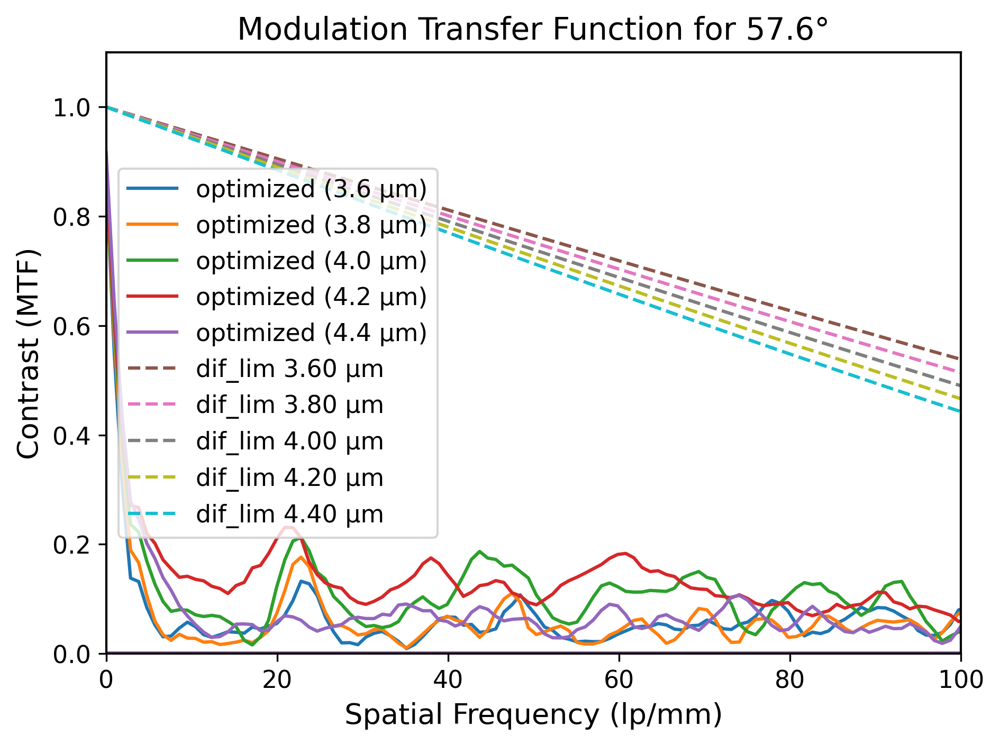

EFFICIENCY PLANE: 6
arr_STREHL: [0.04238406 0.04538108 0.1243466  0.17814363 0.0571194 ]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.01938329 0.04603706 0.13016591 0.16527436 0.06381025]
arr_EER_rel: [0.02190653 0.05240965 0.14904147 0.18997136 0.07232488]
mean STREHL: 0.0894749527054052 +- 0.05345440970853558
mean EER_rel: 0.0971307791028126 +- 0.06259088272282574
EFFICIENCY DEEP: 6
arr_STREHL: [0.01727289 0.02294994 0.0305077  0.03686349 0.04449336]
arr_EER_test: [0.00199704 0.0036687  0.05303576 0.069748   0.00732396]
arr_EER_rel: [0.002257   0.00417653 0.06072656 0.08017047 0.00830125]
mean STREHL: 0.030417475627984907 +- 0.009677127570888506
mean EER_rel: 0.031126360899921234 +- 0.03274817675822109
test region: 7 || angle: 61.489940439172564 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane7.pdf


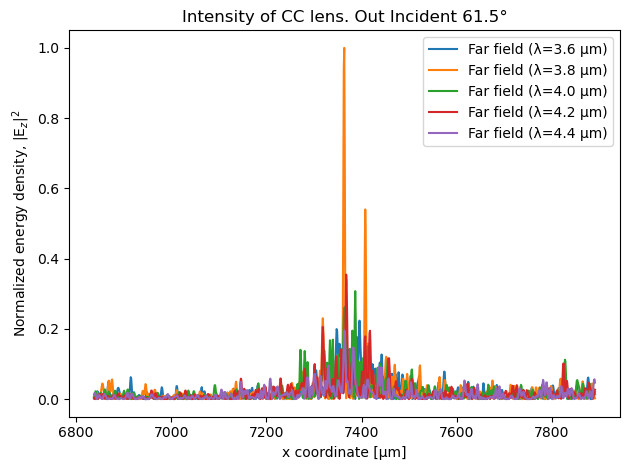

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 5.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 0.00 µm
λ=4.4: FWHM = 0.00 µm
📄 Figure saved to: psf_plot_deep7.pdf


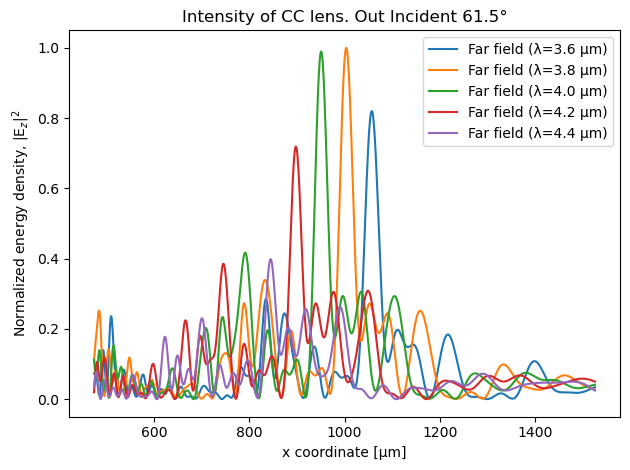

λ=3.6: FWHM = 30.03 µm
λ=3.8: FWHM = 33.03 µm
λ=4.0: FWHM = 31.03 µm
λ=4.2: FWHM = 21.02 µm
λ=4.4: FWHM = 0.00 µm
MTF plot saved to: mtf_plot7.pdf


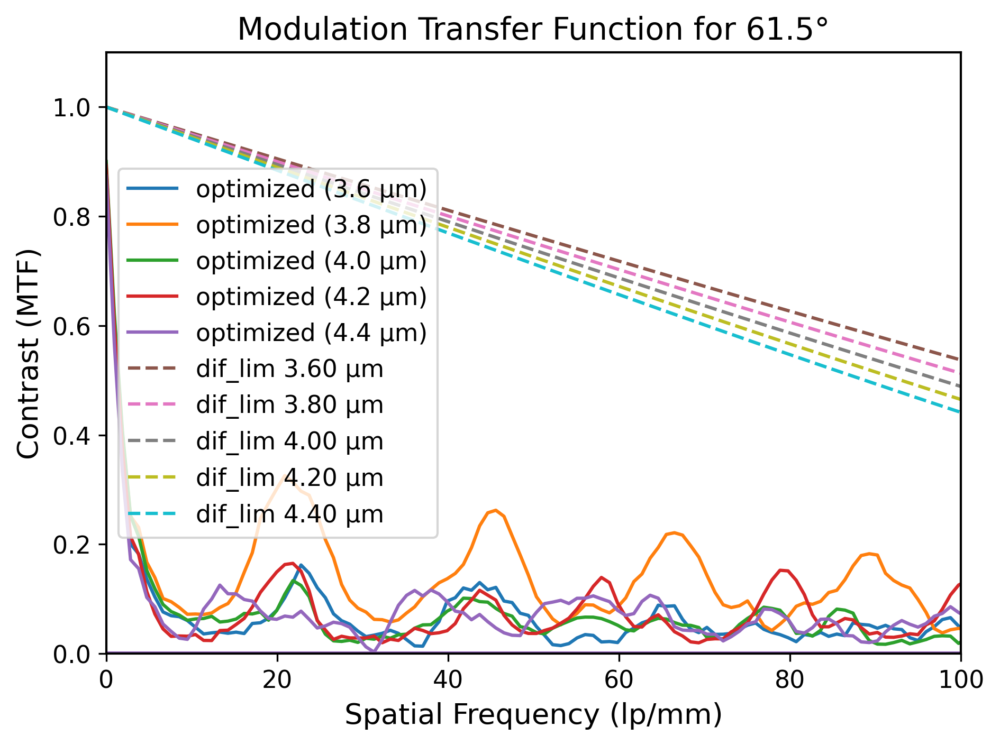

EFFICIENCY PLANE: 7
arr_STREHL: [0.04420856 0.17675847 0.05675349 0.07934778 0.06487536]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.03009498 0.16516518 0.08158188 0.06813253 0.07723378]
arr_EER_rel: [0.03401263 0.18802782 0.09341219 0.0783136  0.0875396 ]
mean STREHL: 0.08438873137040892 +- 0.047574163584760944
mean EER_rel: 0.09626116947390305 +- 0.0504029685544839
EFFICIENCY DEEP: 7
arr_STREHL: [0.0375933  0.03741306 0.037426   0.03278463 0.02662282]
arr_EER_test: [0.00711918 0.08244359 0.02352601 0.0075113  0.03435585]
arr_EER_rel: [0.00804593 0.09385567 0.02693755 0.00863371 0.03894018]
mean STREHL: 0.03436796376155753 +- 0.004278344224652912
mean EER_rel: 0.035282608117084044 +- 0.03151451247739799
test region: 8 || angle: 64.5789521248291 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane8.pdf


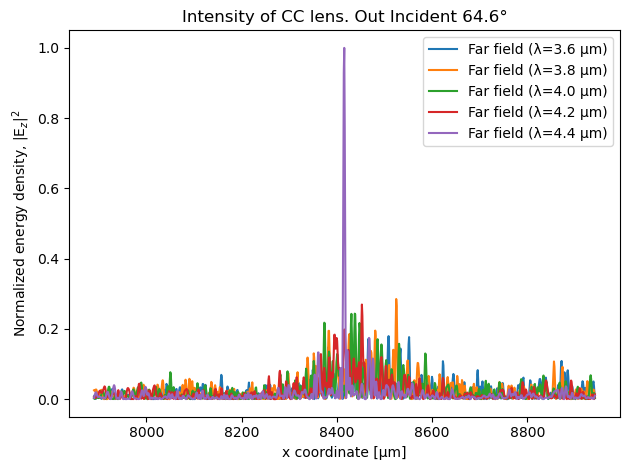

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 0.00 µm
λ=4.4: FWHM = 5.00 µm
📄 Figure saved to: psf_plot_deep8.pdf


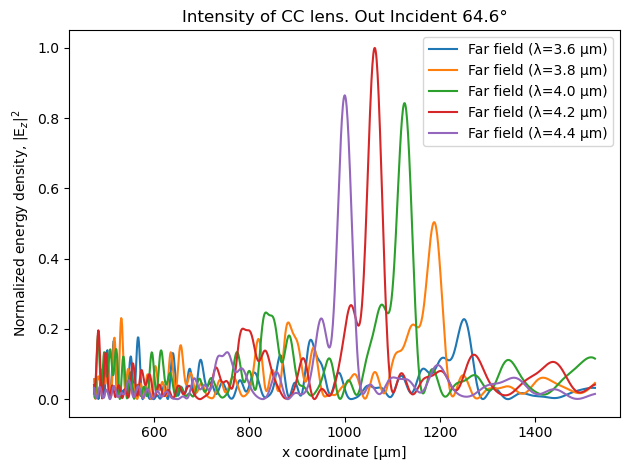

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 5.00 µm
λ=4.0: FWHM = 34.03 µm
λ=4.2: FWHM = 37.04 µm
λ=4.4: FWHM = 32.03 µm
MTF plot saved to: mtf_plot8.pdf


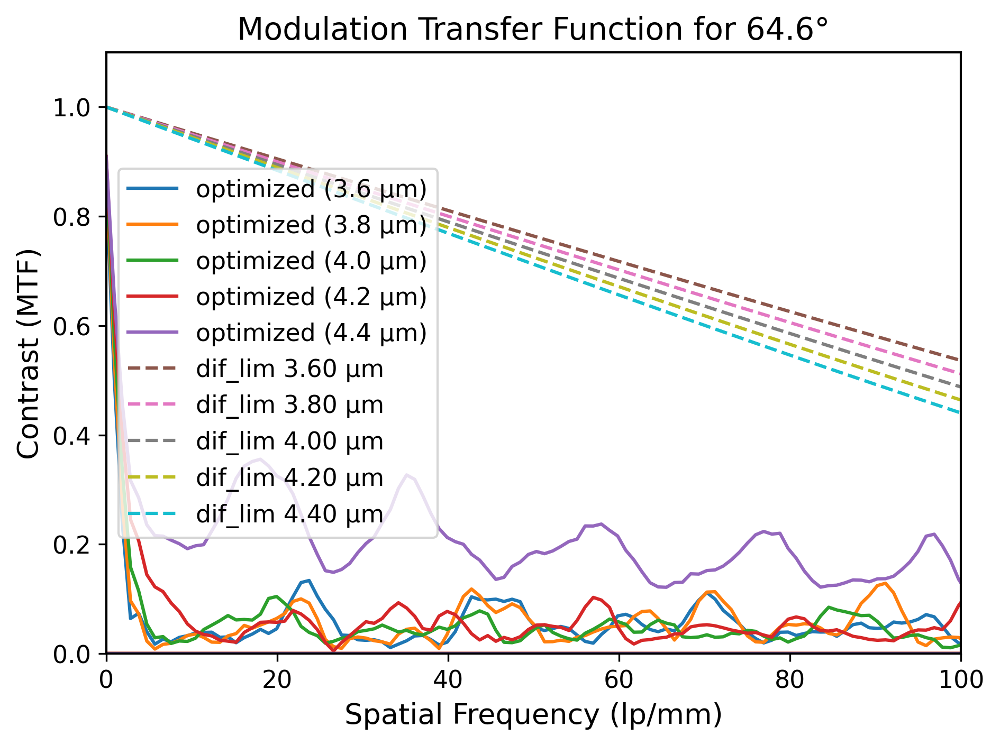

EFFICIENCY PLANE: 8
arr_STREHL: [0.03238098 0.04509434 0.03963192 0.05357688 0.29484158]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.02054869 0.01252142 0.013641   0.05459879 0.26005757]
arr_EER_rel: [0.02322364 0.01425467 0.0156191  0.06275751 0.2947588 ]
mean STREHL: 0.09310514142332119 +- 0.10110580686025361
mean EER_rel: 0.08212274519107894 +- 0.10778406048298042
EFFICIENCY DEEP: 8
arr_STREHL: [0.01900013 0.02785992 0.03670411 0.0477953  0.06111608]
arr_EER_test: [0.00660131 0.00524304 0.00286127 0.01932703 0.14458157]
arr_EER_rel: [0.00746065 0.00596879 0.00327619 0.02221507 0.16387406]
mean STREHL: 0.03849510750888881 +- 0.014795749124753057
mean EER_rel: 0.04055895240820614 +- 0.06200821674953015
test region: 9 || angle: 67.09712323501574 || include elements: 186


FloatProgress(value=0.0, description='0% done ', max=200.0)

📄 Figure saved to: psf_plot_plane9.pdf


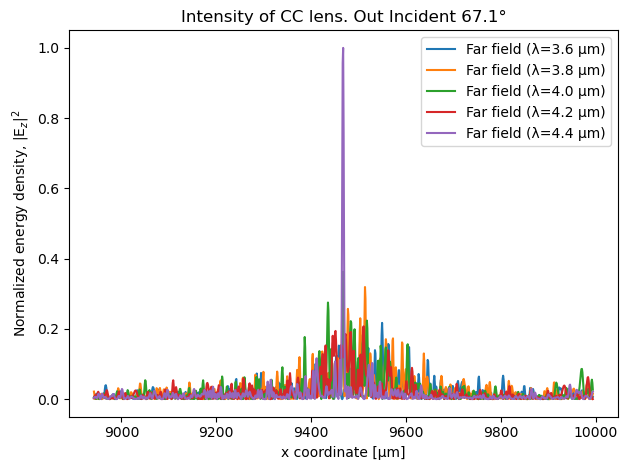

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 0.00 µm
λ=4.0: FWHM = 0.00 µm
λ=4.2: FWHM = 0.00 µm
λ=4.4: FWHM = 5.00 µm
📄 Figure saved to: psf_plot_deep9.pdf


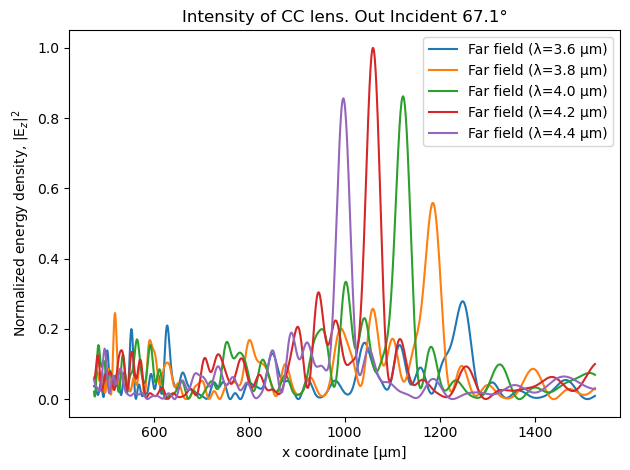

λ=3.6: FWHM = 0.00 µm
λ=3.8: FWHM = 17.02 µm
λ=4.0: FWHM = 34.03 µm
λ=4.2: FWHM = 36.03 µm
λ=4.4: FWHM = 30.03 µm
MTF plot saved to: mtf_plot9.pdf


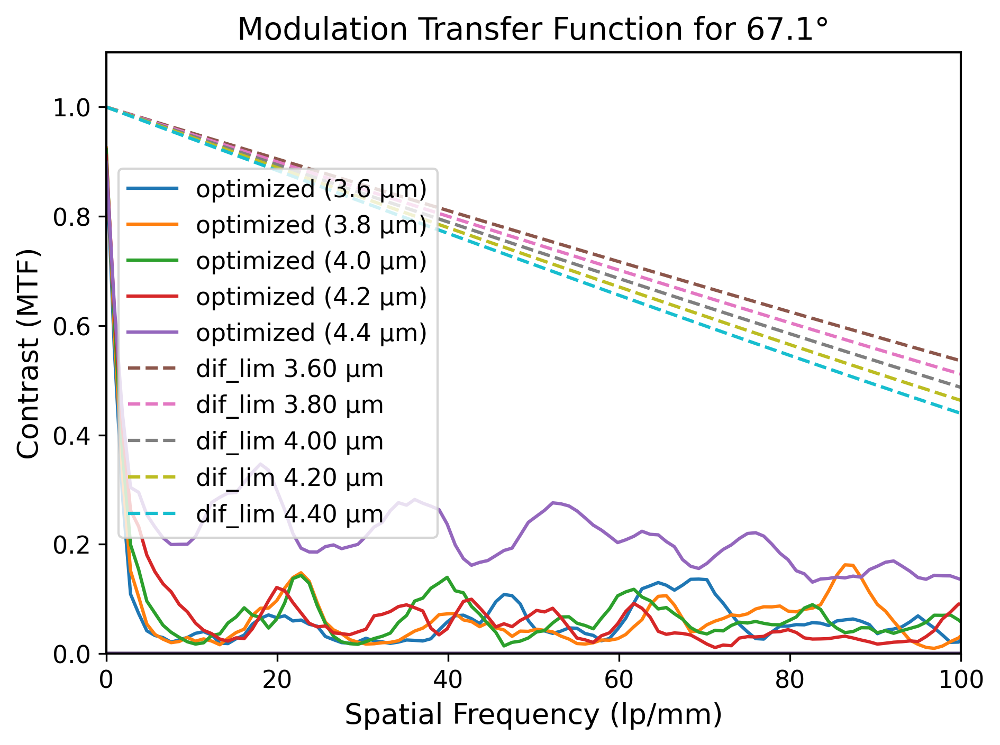

EFFICIENCY PLANE: 9
arr_STREHL: [0.04087815 0.05312861 0.06202839 0.04241747 0.30343737]
arr_EER_airy: [0.88481758 0.87840819 0.87335362 0.86999616 0.88227245]
arr_EER_test: [0.00702305 0.04832189 0.06393341 0.06414326 0.2648489 ]
arr_EER_rel: [0.00793729 0.05501074 0.07320449 0.07372821 0.30018947]
mean STREHL: 0.10037799687401634 +- 0.10181941044859372
mean EER_rel: 0.10201404073341865 +- 0.10194442186205022
EFFICIENCY DEEP: 9
arr_STREHL: [0.02017837 0.02801334 0.03671037 0.0458883  0.05572307]
arr_EER_test: [0.00342451 0.0214634  0.02999141 0.0110469  0.1299141 ]
arr_EER_rel: [0.0038703  0.02443443 0.03434051 0.01269765 0.14724941]
mean STREHL: 0.03730269069330463 +- 0.01259292126369302
mean EER_rel: 0.044518457923720556 +- 0.0523935951150537


In [6]:
# ____ Multi-angle ____
# GET DATA
opt_zone_start = 0
opt_zone_end = conf.n_angles
# opt_zone_end = 1
for i in range(opt_zone_start, opt_zone_end):
    if i == 0:
        is_center=True
        loc_symmetry = None
    else:
        is_center=False
        loc_symmetry = None

    loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
    loc_rt_np = rt_np_global[:loc_orders]
    loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
    resolutions = nf.AdaptiveResolution(
        drt=loc_drt_np,
        x_dim=conf.x_dim,
        h_dim= conf.h_dim,
    ).generate()
    
    test_loc_a = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
    test_loc_h = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
    print(f"=====================================================")
    print(f"test region: {i} || angle: {angle_in_deg[i]} || include elements: {len(test_loc_a)}")
    res_axial_I, res_deep_I = cf.test_loc(
        stack_batch_src[i],
        rt_np = loc_rt_np, drt_np=loc_drt_np, midrt_np=loc_midrt_np,
        resolutions=resolutions,
        is_center = is_center,
        loc_symmetry=loc_symmetry,
        locNearRegion=locNearRegion,
        best_a_params=test_loc_a,
        best_h_params=test_loc_h,
        cut_shift = 0.0,
        is_plot_sim = False,
        is_plot_cross = False,
    )
    
    # ASSUMING DATA
    res_axial_I_norm = res_axial_I / res_axial_I.max()
    res_deep_I_norm = res_deep_I / res_deep_I.max()
    abscissa = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], i * conf.diaphragm)
    abscissa_deep = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], conf.f)
    
    # Crop if needed
    # I_crop, absc_crop = help_functions.recenter_and_crop(IOptimized_scaled, abscissa, ref_index=0)

    # Outputs data plane
    nf.plot_intensity(
        res_axial_I_norm,
        out_angle_in_deg=angle_in_deg[i],
        wavelength_array=conf.inc_wavelength_array,
        abscissa=abscissa,
        isfwhm=True,
        save_path=f"psf_plot_plane{i}.pdf",
    )
    
    # Outputs data deep
    nf.plot_intensity(
        res_deep_I_norm,
        out_angle_in_deg=angle_in_deg[i],
        wavelength_array=conf.inc_wavelength_array,
        abscissa=abscissa_deep,
        isfwhm=True,
        save_path=f"psf_plot_deep{i}.pdf",
    )
    if i == 0:
        nf.plot_psf(
            conf.inc_nfreq, conf.spot_ff,
            res_axial_I_norm,
            abscissa=abscissa,
            save_path = f"psf_plot{i}.pdf", 
            save_format="pdf",
            colorbar_to_1=False,
        )
    
    nf.plot_mtf(
        conf.spot_ff, res_axial_I,
        max_view=100,
        in_angle_in_deg=angle_after_refraction_in_deg[i],
        out_angle_in_deg=angle_in_deg[i],
        dif_lim=True, 
        smooth=True,
        I_mtf_theory = None,
        save_path=f"mtf_plot{i}.pdf",
        save_format="pdf"
    )
    
    arr_STREHL, arr_EER_airy, arr_EER_test, arr_EER_rel, mean_STREHL, std_STREHL, mean_EER_rel, std_EER_rel = nf.get_focusing_efficiency(
        airy_focus=IAiry, 
        test_focus=res_axial_I,
        abscissa=abscissa,
        call_id=i,
        results_filename="efficiency_plane.csv"
        )
    
    arr_STREHL_d, _, arr_EER_test_d, arr_EER_rel_d, mean_STREHL_d, std_STREHL_d, mean_EER_rel_d, std_EER_rel_d = nf.get_focusing_efficiency(
    airy_focus=IAiry, 
    test_focus=res_deep_I,
    abscissa=abscissa_deep,
    call_id=i,
    results_filename="efficiency_deep.csv"
    )
    
    print(f"EFFICIENCY PLANE: {i}")
    print(f"arr_STREHL: {arr_STREHL}") 
    print(f"arr_EER_airy: {arr_EER_airy}") 
    print(f"arr_EER_test: {arr_EER_test}") 
    print(f"arr_EER_rel: {arr_EER_rel}")
    print(f"mean STREHL: {mean_STREHL} +- {std_STREHL}")
    print(f"mean EER_rel: {mean_EER_rel} +- {std_EER_rel}")
    print (f"EFFICIENCY DEEP: {i}")
    print(f"arr_STREHL: {arr_STREHL_d}") 
    print(f"arr_EER_test: {arr_EER_test_d}") 
    print(f"arr_EER_rel: {arr_EER_rel_d}")
    print(f"mean STREHL: {mean_STREHL_d} +- {std_STREHL_d}")
    print(f"mean EER_rel: {mean_EER_rel_d} +- {std_EER_rel_d}")

In [ ]:
# # ____ Single angle rotate____
# # GET DATA
# opt_zone_start = 0
# i = opt_zone_start
# test_loc_a = cf.get_local_tensor_from_global(global_a_params, i, conf.loc_orders)
# test_loc_h = cf.get_local_tensor_from_global(global_h_params, i, conf.loc_orders)
# print(f"test region: {i} || angle: {angle_in_deg[i]} || include elements: {len(test_loc_a)}")
# res_plane_I, res_deep_I = cf.test_loc_rotate(
#     i, 
#     conf.loc_orders, 
#     stack_batch_src[i],
#     rt_np, 
#     resolutions,
#     locNearRegion, 
#     test_loc_a, 
#     test_loc_h,
#     cut_shift = -1.0,
#     is_plot_sim = True,
#     is_plot_cross = True,
# )

### 4. GDS or STL

In [ ]:
# global_a_params = torch.load("global_a_params_536.pt", weights_only=True)
# global_h_params = torch.load("global_h_params_536.pt", weights_only=True)

In [ ]:
"""
GDS
"""

# nf.generate_lens_gds_2params(global_a_params, global_h_params, conf.orders, rt_np_global, MIN_POLY_AREA=0.08, Q = 25, w = conf.w, filename='gds_1param_6mm_ang0_33.7_aSi_h0.6.gds', cell_name = 'LENS_CELL1', n_layers=1)

# nf.generate_lens_gds_cc_linear(global_a_params, rt_np, conf.orders, w = conf.w, Q = conf.Q, W = 100, filename="gds_1param_linear_6mm_ang0_45_aSi_h1_sub10.gds")

# nf.generate_lens_gds_grid(global_a_params, conf.orders, rt_np, stack= conf.stack, Q = conf.Q, w = conf.w, W = 100,filename='gds_1param_grid_6mm_ang0_45_aSi_h1_sub10.gds')

# nf.generate_lens_gds_2params(global_a_params, global_h_params, conf.orders, rt_np, Q = conf.Q, w = conf.w, filename='gds_2param_small.gds', cell_name = 'LENS_CELL_NEW', n_layers=conf.h_dim)

"""
STL
"""

# nf.generate_lens_stl_cc_linear(global_a_params, global_h_params, conf.orders-1, rt_np, Q = 50, w = conf.w, N = 2, substrate_thickness = 10,filename='2param_small.stl')

# nf.generate_lens_stl_grid(global_a_params, global_h_params, conf.orders, rt_np, stack= conf.stack, Q = 100, w = conf.w, substrate_thickness = 5,filename='2param_grid.stl')